# 02 The nine anomaly checks

**Business question.** Which transactions should an auditor look at, and can a fixed set of automated tests find the problems a manual review is looking for, without burying the reviewer in false alarms?

`src/checks.py` implements nine checks commonly used in AP and P-card continuous auditing. Each returns the flagged transactions with the evidence behind the flag. Because the data is synthetic, the generator's planted-anomaly labels let us measure each check's **precision** (share of flags that are the anomaly the check targets) and **recall** (share of planted anomalies caught). Labels are only used here, never inside the checks.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=["#2a6fb0", "#e0702b", "#2e9e6b", "#c9a227", "#8a5cc2", "#d0475a", "#5a6b7b", "#3fb3c4"]),
})

In [2]:
from etl import run_etl, connect, DB_PATH
from checks import CHECKS, CHECK_DESCRIPTIONS, run_all_checks, benford_by_group, BENFORD_P
from evaluation import precision_recall

if not DB_PATH.exists():
    run_etl()
conn = connect(DB_PATH)
labels = pd.read_csv(RAW / "anomaly_labels.csv")
results, timing = run_all_checks(conn)
n_txn = pd.read_sql_query("SELECT COUNT(*) n FROM transactions", conn).n.iloc[0]
print(f"{n_txn:,} transactions scanned by {len(CHECKS)} checks")
timing.assign(seconds=timing.seconds.round(3))

417,470 transactions scanned by 9 checks


,check,flagged_rows,seconds
0,duplicate_payment,592,1.743
1,split_purchase,818,0.223
2,weekend_holiday_posting,641,0.240
3,benford_deviation,2688,1.366
4,round_dollar,519,0.034
5,vendor_amount_outlier,381,0.963
6,new_vendor_large_payment,154,0.026
7,self_approval,299,0.050
8,sequence_gap,185,0.493


In [3]:
def show(name, n=5):
    res = results[name]
    truth = set(labels.loc[labels.anomaly_type == name, "txn_id"])
    hit = res.txn_id.isin(truth)
    print(f"{name}: {len(res):,} flagged, {hit.sum():,} of {len(truth):,} planted caught")
    return res.head(n)

## Check 1: Duplicate payments

**Rule.** Same vendor, same amount and same invoice number paid more than once. Invoice numbers are normalised first (upper case, punctuation and whitespace removed), because duplicates usually slip through when the second copy is keyed slightly differently (`INV-004512` vs `inv004512`). The first posting is treated as the original and later ones are flagged.

**Why it matters.** Duplicate payments are the most common recoverable AP loss.

In [4]:
show("duplicate_payment")

duplicate_payment: 592 flagged, 592 of 635 planted caught


,txn_id,original_txn_id,original_posting_date,days_after_original
0,1362047,1359282,2025-02-03,7
1,1047745,1045482,2022-11-09,6
2,1362048,1357289,2025-01-28,13
3,1211925,1203086,2024-01-02,21
4,1072000,1067167,2023-01-06,13


## Check 2: Split purchases

**Rule.** Two or more payments by the same requester to the same vendor within 7 days, each between 75% and 100% of an approval threshold ($5,000 needs department-head approval, $25,000 needs a competitive bid), that together exceed the threshold.

**Why it matters.** Splitting an order to stay under a threshold bypasses the control the threshold exists to enforce.

In [5]:
show("split_purchase")

split_purchase: 818 flagged, 682 of 682 planted caught


,txn_id,threshold,n_in_window,window_total
0,1323034,25000.0,4,88586.89
1,1137311,25000.0,3,63663.03
2,1323035,25000.0,4,88586.89
3,1323036,25000.0,4,88586.89
4,1136544,25000.0,3,67544.51


## Check 3: Weekend and holiday postings

**Rule.** AP vouchers posted on a Saturday, Sunday or university holiday. P-card transactions are excluded because card networks settle every day.

**Why it matters.** AP batches run on business days; an off-calendar posting points to manual intervention outside normal supervision.

In [6]:
show("weekend_holiday_posting")

weekend_holiday_posting: 641 flagged, 402 of 417 planted caught


,txn_id,posting_date,reason
0,1000257,2022-07-04,Independence Day
1,1000258,2022-07-04,Independence Day
2,1003146,2022-07-17,Sunday
3,1009891,2022-08-06,Saturday
4,1009892,2022-08-06,Saturday


## Check 4: Benford's law (first digit), by requester

**Rule.** For every requester with at least 100 transactions, compare the first-digit distribution of their amounts with Benford's law. Flag the requester when the mean absolute deviation (MAD) exceeds Nigrini's 0.015 non-conformity cut-off **and** a chi-square test rejects conformity at p < 0.001 (the chi-square guard stops small samples being flagged on noise). All transactions of a flagged requester are returned for review.

**Why it matters.** Naturally occurring amounts follow Benford's law; invented amounts usually do not, because people over-use middle and high first digits.

In [7]:
show("benford_deviation")

benford_deviation: 2,688 flagged, 2,686 of 2,686 planted caught


,txn_id,requester_id,mad,p_value
0,1000025,E0063,0.111998,7.435795e-177
1,1000354,E0404,0.114157,5.622761e-71
2,1000387,E0063,0.111998,7.435795e-177
3,1000391,E0392,0.110507,4.748394e-154
4,1001028,E0062,0.108015,7.256454e-151


392 requesters tested, 6 flagged
MAD of conforming requesters: median 0.0094, 95th pct 0.0201


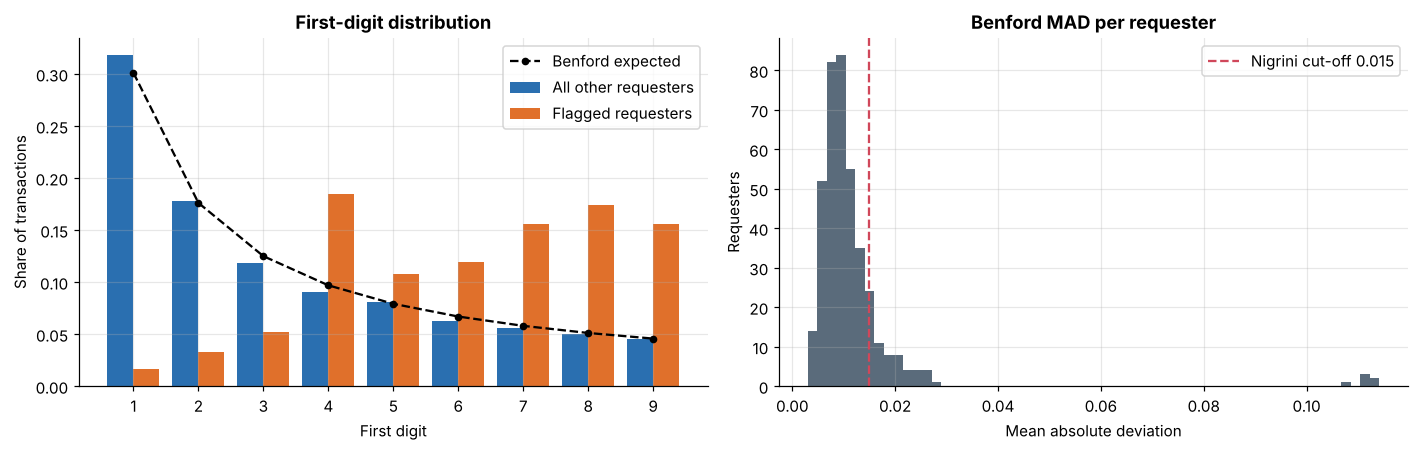

In [8]:
amt = pd.read_sql_query("SELECT requester_id, amount FROM transactions", conn)
tests = benford_by_group(amt, "requester_id")
flagged_people = results["benford_deviation"].requester_id.unique()
print(f"{len(tests)} requesters tested, {len(flagged_people)} flagged")
print("MAD of conforming requesters: median {:.4f}, 95th pct {:.4f}".format(
    tests.loc[~tests.requester_id.isin(flagged_people), "mad"].median(),
    tests.loc[~tests.requester_id.isin(flagged_people), "mad"].quantile(0.95)))

def digit_dist(s):
    a = s.abs(); a = a[a >= 10]
    d = (a / 10 ** np.floor(np.log10(a))).astype(int).clip(1, 9)
    return d.value_counts(normalize=True).reindex(range(1, 10), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
digits = np.arange(1, 10)
axes[0].bar(digits - 0.2, digit_dist(amt.loc[~amt.requester_id.isin(flagged_people), "amount"]), 0.4, label="All other requesters")
axes[0].bar(digits + 0.2, digit_dist(amt.loc[amt.requester_id.isin(flagged_people), "amount"]), 0.4, label="Flagged requesters")
axes[0].plot(digits, BENFORD_P, "k--o", ms=4, label="Benford expected")
axes[0].set_title("First-digit distribution"); axes[0].set_xlabel("First digit"); axes[0].set_ylabel("Share of transactions")
axes[0].set_xticks(digits); axes[0].legend()
axes[1].hist(tests.mad, bins=60, color="#5a6b7b")
axes[1].axvline(0.015, color="#d0475a", ls="--", label="Nigrini cut-off 0.015")
axes[1].set_title("Benford MAD per requester"); axes[1].set_xlabel("Mean absolute deviation"); axes[1].set_ylabel("Requesters")
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "02_benford.png"); plt.show()

## Check 5: Round-dollar amounts

**Rule.** Exact multiples of $1,000 at or above $1,000. Student stipends and fellowships are paid in fixed award amounts by design, so that account group is excluded; the cell below shows what the check would return without the exclusion.

**Why it matters.** Genuine invoices carry tax, freight and unit prices; round amounts are a classic sign of estimates, advances or invented payments.

In [9]:
raw_round = pd.read_sql_query("SELECT * FROM v_chk_round_dollar", conn)
print(f"Without the stipend exclusion: {len(raw_round):,} rows flagged "
      f"({(raw_round.account_group == 'Student Support').sum():,} of them stipends / fellowships)")
show("round_dollar")

Without the stipend exclusion: 6,335 rows flagged (5,816 of them stipends / fellowships)
round_dollar: 519 flagged, 517 of 517 planted caught


,txn_id,amount,account_code,account_group
0,1003526,1000.0,56020,Auxiliary
1,1013105,1000.0,54010,Travel
2,1022395,1000.0,51040,Services
3,1025420,1000.0,54020,Travel
4,1029324,1000.0,51020,Supplies


## Check 6: Vendor amount outliers (robust z-score)

**Rule.** For each vendor with at least 20 AP payments, compute a robust z-score of log(amount) using the vendor's median and median absolute deviation, and flag payments with z > 4. Logs are used because invoice amounts are right-skewed; median and MAD are used so the outliers do not inflate the baseline they are judged against.

**Why it matters.** A payment many times larger than anything the vendor normally bills is either an error (extra zero, wrong vendor) or worth a question.

In [10]:
show("vendor_amount_outlier")

vendor_amount_outlier: 381 flagged, 191 of 259 planted caught


,txn_id,vendor_id,amount,vendor_median_amount,robust_z
0,1110394,V12583,893.85,154.23,4.210181
1,1243893,V12583,938.00,154.23,4.325702
2,1207554,V12546,986.77,249.76,4.094345
3,1025420,V10100,1000.00,111.36,4.431187
4,1363914,V12583,1000.00,154.23,4.479066


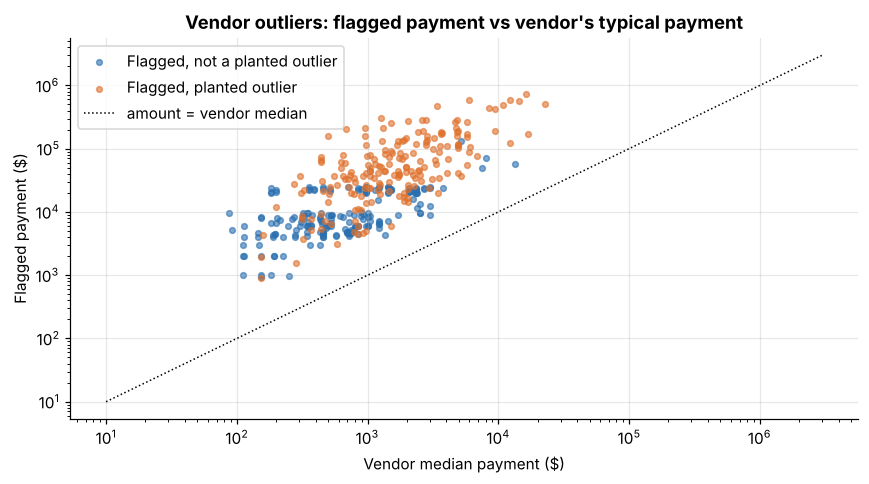

In [11]:
zs = results["vendor_amount_outlier"]
truth_z = set(labels.loc[labels.anomaly_type == "vendor_amount_outlier", "txn_id"])
fig, ax = plt.subplots(figsize=(8, 4.5))
hit = zs.txn_id.isin(truth_z)
ax.scatter(zs.loc[~hit, "vendor_median_amount"], zs.loc[~hit, "amount"], s=14, alpha=0.6, label="Flagged, not a planted outlier")
ax.scatter(zs.loc[hit, "vendor_median_amount"], zs.loc[hit, "amount"], s=14, alpha=0.6, label="Flagged, planted outlier")
lim = [10, 3e6]
ax.plot(lim, lim, "k:", lw=1, label="amount = vendor median")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Vendor median payment ($)"); ax.set_ylabel("Flagged payment ($)")
ax.set_title("Vendor outliers: flagged payment vs vendor's typical payment")
ax.legend(); plt.tight_layout(); plt.show()

## Check 7: Large payments to new vendors

**Rule.** Payments of $25,000 or more posted less than 90 days after the vendor was created in the vendor master.

**Why it matters.** Fictitious-vendor schemes typically set up a vendor and pay it quickly, before anyone notices it.

In [12]:
show("new_vendor_large_payment")

new_vendor_large_payment: 154 flagged, 71 of 82 planted caught


,txn_id,vendor_id,vendor_created_date,amount,vendor_age_days
0,1271351,V13148,2024-04-18,25127.59,67
1,1274001,V13148,2024-04-18,25138.60,74
2,1239886,V13341,2024-01-14,25358.13,81
3,1279465,V13044,2024-04-18,25669.80,88
4,1071627,V13321,2022-10-30,25807.90,79


## Check 8: Self-approval

**Rule.** The requester and the approver on a transaction are the same employee.

**Why it matters.** It is a direct breach of segregation of duties; every hit needs an explanation.

In [13]:
show("self_approval")

self_approval: 299 flagged, 299 of 299 planted caught


,txn_id,requester_id,approver_id,amount
0,1005956,E0032,E0032,1284.41
1,1010889,E0315,E0315,298.59
2,1011805,E0211,E0211,4997.16
3,1011836,E0141,E0141,330.81
4,1014952,E0003,E0003,961.06


## Check 9: Gaps in the AP voucher sequence

**Rule.** AP vouchers are numbered sequentially within each fiscal year. A window function finds every jump in the sequence; the voucher after each gap is flagged with the number of missing vouchers. Quarantined ETL rows still count as issued numbers, so data-quality rejects do not create false gaps.

**Why it matters.** Missing numbers can mean deleted or suppressed vouchers; each gap should tie to the void register.

In [14]:
show("sequence_gap")

sequence_gap: 185 flagged, 140 of 140 planted caught


,txn_id,voucher_no,prev_n,missing_vouchers
0,1003464,AP23-0000731,729,1
1,1006436,AP23-0002163,2161,1
2,1008236,AP23-0003114,3112,1
3,1010837,AP23-0004485,4483,1
4,1013335,AP23-0005775,5773,1


## Precision and recall against the planted anomalies

Row-level scoring: a flag is a true positive only if the row carries the label of the anomaly that check is designed to find.

In [15]:
pr = precision_recall(results, labels)
pr["description"] = pr.check.map(CHECK_DESCRIPTIONS)
pr.round(3)

,check,flagged,planted,true_positives,precision,recall,f1,description
0,duplicate_payment,592,635,592,1.000,0.932,0.965,"Same vendor, amount and normalised invoice num..."
1,split_purchase,818,682,682,0.834,1.000,0.909,Near-threshold payments by one requester to on...
2,weekend_holiday_posting,641,417,402,0.627,0.964,0.760,AP voucher posted on a weekend or university h...
3,benford_deviation,2688,2686,2686,0.999,1.000,1.000,Requester's amounts fail the Benford first-dig...
4,round_dollar,519,517,517,0.996,1.000,0.998,"Exact multiple of $1,000 (stipend / fellowship..."
5,vendor_amount_outlier,381,259,191,0.501,0.737,0.597,Robust z-score of log(amount) > 4 within the v...
6,new_vendor_large_payment,154,82,71,0.461,0.866,0.602,$25k+ paid to a vendor created < 90 days befor...
7,self_approval,299,299,299,1.000,1.000,1.000,Requester approved their own transaction
8,sequence_gap,185,140,140,0.757,1.000,0.862,Voucher immediately after a missing AP voucher...


In [16]:
overall_flagged = set().union(*[set(r.txn_id) for r in results.values()])
all_planted = set(labels.txn_id)
print(f"Distinct transactions flagged by at least one check: {len(overall_flagged):,} "
      f"({len(overall_flagged) / n_txn:.2%} of the ledger)")
print(f"Planted anomalous transactions caught by at least one check: "
      f"{len(overall_flagged & all_planted):,} of {len(all_planted):,} ({len(overall_flagged & all_planted) / len(all_planted):.1%})")
print(f"Share of flagged transactions that are planted anomalies of any type: "
      f"{len(overall_flagged & all_planted) / len(overall_flagged):.1%}")
print(f"Macro-average precision {pr.precision.mean():.3f}, recall {pr.recall.mean():.3f}")

Distinct transactions flagged by at least one check: 6,067 (1.45% of the ledger)
Planted anomalous transactions caught by at least one check: 5,584 of 5,717 (97.7%)
Share of flagged transactions that are planted anomalies of any type: 92.0%
Macro-average precision 0.797, recall 0.944


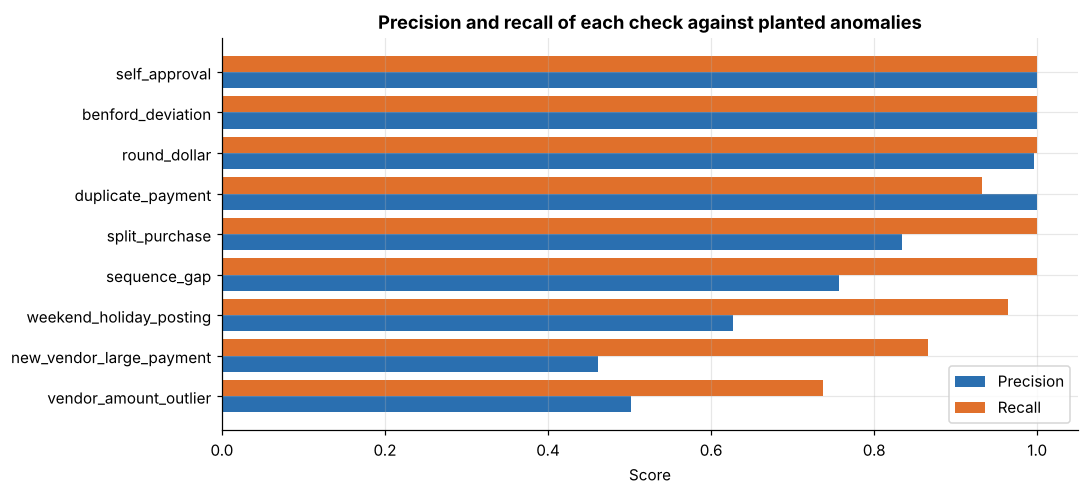

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.6))
order = pr.sort_values("f1")
y = np.arange(len(order))
ax.barh(y - 0.2, order.precision, 0.4, label="Precision")
ax.barh(y + 0.2, order.recall, 0.4, label="Recall")
ax.set_yticks(y); ax.set_yticklabels(order.check)
ax.set_xlim(0, 1.05); ax.set_xlabel("Score")
ax.set_title("Precision and recall of each check against planted anomalies")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG / "02_precision_recall.png"); plt.show()

## What are the false positives?

A false positive is not necessarily a wasted review. The table splits each check's non-target flags into rows that are a *different* planted anomaly (the check still pointed the reviewer at a real problem) and rows that are genuinely clean.

In [18]:
lab_any = labels.groupby("txn_id").anomaly_type.apply(set)
rows = []
for name, res in results.items():
    ids = res.txn_id
    target = ids.map(lambda t: name in lab_any.get(t, set()))
    other = ids.map(lambda t: bool(lab_any.get(t, set()) - {name}) and name not in lab_any.get(t, set()))
    rows.append({"check": name, "flagged": len(ids), "target_anomaly": int(target.sum()),
                 "other_planted_anomaly": int(other.sum()), "clean": int((~target & ~other).sum())})
fp = pd.DataFrame(rows)
fp

,check,flagged,target_anomaly,other_planted_anomaly,clean
0,duplicate_payment,592,592,0,0
1,split_purchase,818,682,40,96
2,weekend_holiday_posting,641,402,3,236
3,benford_deviation,2688,2686,2,0
4,round_dollar,519,517,0,2
5,vendor_amount_outlier,381,191,165,25
6,new_vendor_large_payment,154,71,4,79
7,self_approval,299,299,0,0
8,sequence_gap,185,140,0,45


In [19]:
wk = results["weekend_holiday_posting"]
clean_wk = wk[~wk.txn_id.isin(labels.txn_id)]
print("Clean weekend/holiday flags by posting date (top 5):")
print(clean_wk.posting_date.value_counts().head().to_string())
nv = results["new_vendor_large_payment"]
print(f"\nNew-vendor flags on vendors with no planted payment: {(~nv.txn_id.isin(labels.txn_id)).sum()}")
missed_nv = labels[(labels.anomaly_type == "new_vendor_large_payment") & ~labels.txn_id.isin(nv.txn_id)]
age = pd.read_sql_query("SELECT txn_id, CAST(julianday(posting_date) - julianday(vendor_created_date) AS INT) AS age FROM v_txn", conn)
print("Vendor age (days) at posting for missed new-vendor payments:", sorted(age[age.txn_id.isin(missed_nv.txn_id)].age.tolist()))

Clean weekend/holiday flags by posting date (top 5):
posting_date
2024-06-30    236

New-vendor flags on vendors with no planted payment: 79


Vendor age (days) at posting for missed new-vendor payments: [104, 108, 114, 119, 123, 124, 128, 134, 136, 137, 142]


In [20]:
pr.to_csv(PROC / "check_precision_recall.csv", index=False)
conn.close()

## Findings

* The nine checks scanned **417,470 transactions** and flagged **6,067 distinct transactions (1.45% of the ledger)**. Those flags caught **5,584 of the 5,717 planted anomalous transactions (97.7%)**, and **92.0% of flagged transactions are a planted anomaly of some type**. Macro-average precision is 0.797 and macro-average recall 0.944.
* Near-perfect checks: self-approval (precision 1.000, recall 1.000), Benford by requester (0.999 / 1.000: all 6 fabricating requesters flagged, MAD about 0.11 against a 0.0094 median for everyone else), round-dollar (0.996 / 1.000) and duplicate payments (1.000 / 0.932; the 43 misses are duplicates whose invoice number was re-keyed with transposed digits, which a normalised exact match cannot catch).
* Split purchases (0.834 / 1.000) and sequence gaps (0.757 / 1.000) catch every planted case; their extra flags are mostly genuine near-threshold buying and 45 voucher numbers cancelled outside the planted set, which a void register would clear.
* Weekend/holiday postings (0.627 / 0.964): all 236 clean flags fall on Sunday 30 June 2024, the fiscal year-end close. A one-line exception for documented close dates would lift precision to 0.99.
* The two judgement-heavy checks are the noisiest. Vendor outliers (0.501 / 0.737): 165 of the 190 non-target flags are other planted anomalies (83 split-purchase pieces, 58 fabricated Benford amounts and 24 round-dollar payments that are also unusually large for their vendor), so only 25 flags are clean. New-vendor large payments (0.461 / 0.866): 79 clean flags are legitimate large first orders, and the 11 misses were paid 104 to 142 days after vendor set-up, outside the 90-day window.
* Excluding stipend and fellowship accounts matters: without it the round-dollar check would flag 6,335 rows, 5,816 of them fixed-amount stipends.